In [20]:
import pandas as pd
import numpy as np
#1.1
Sig_Eqs = pd.read_csv(
    "earthquakes-2026-10-27_22-28-57_+0800.tsv",
    sep="\t",
    low_memory=False
)

# 解决历史名称不同
country_map = {
    "TURKEY-CIS": "TURKEY",
    "USSR": "RUSSIA",
    "BURMA": "MYANMAR (BURMA)",
    "USA TERRITORY": "USA",
    "UK TERRITORY": "UK",
    "CZECHOSLOVAKIA": "CZECH REPUBLIC",
    "YUGOSLAVIA": "SERBIA",
}
Sig_Eqs["Country_std"] = (
    Sig_Eqs["Country"]
    .map(country_map)
    .fillna(Sig_Eqs["Country"])
)

# 死亡人数转数值
Sig_Eqs["Total Deaths"] = pd.to_numeric(
    Sig_Eqs["Total Deaths"], errors="coerce"
).fillna(0)

#按标准化国家分组求和，降序取前 20
deaths_by_country = (
    Sig_Eqs.groupby("Country_std")["Total Deaths"]
    .sum()
    .sort_values(ascending=False)
)

top20 = deaths_by_country.head(20)
print("Top 20 countries by total earthquake deaths:")
print(top20)


Top 20 countries by total earthquake deaths:
Country_std
CHINA           2106542.0
TURKEY          1008867.0
IRAN             761641.0
ITALY            417297.0
SYRIA            358326.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0
Name: Total Deaths, dtype: float64


Mean annual count before 1900: 1.99
Mean annual count from 1900 onward: 19.49


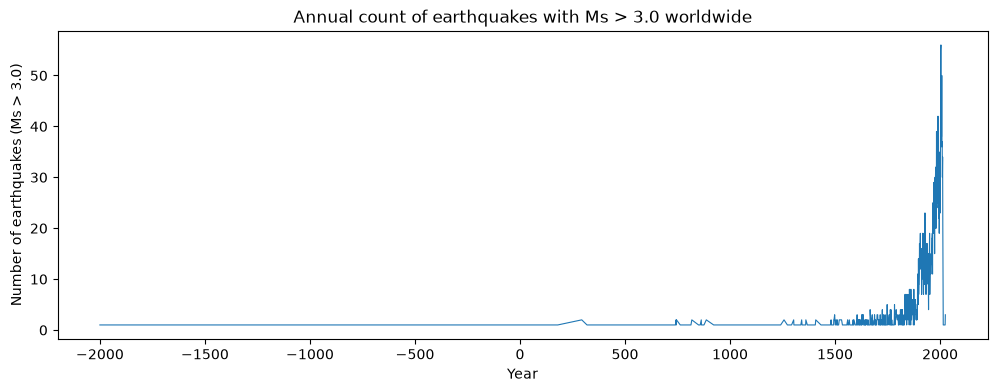

In [23]:
# 1.2 
# 把 Ms 转成数值，非数值变 NaN
Sig_Eqs["Ms"] = pd.to_numeric(Sig_Eqs["Ms"], errors="coerce")

# 只保留 Ms > 3.0 的记录
ms_gt3 = Sig_Eqs[Sig_Eqs["Ms"] > 3.0]

# 按 Year 分组计数（size() 返回每组的行数，即每年地震条数）
# sort_index() 年份从小到大排列
counts_per_year = ms_gt3.groupby("Year").size().sort_index()

counts_per_year.plot(
    kind="line",
    figsize=(12, 4),
    title="Annual count of earthquakes with Ms > 3.0 worldwide",
    xlabel="Year",
    ylabel="Number of earthquakes (Ms > 3.0)",
    linewidth=0.8
)

years = counts_per_year.index.to_numpy()   # 年份数组
vals  = counts_per_year.to_numpy()         # 每年计数数组
early = vals[years < 1900].mean() if (years < 1900).any() else np.nan
late  = vals[years >= 1900].mean() if (years >= 1900).any() else np.nan
print(f"Mean annual count before 1900: {early:.2f}")
print(f"Mean annual count from 1900 onward: {late:.2f}")

In [24]:
def CountEq_LargestEq(country):
  
    #取出该国的所有记录，该国地震总数
    sub = Sig_Eqs[Sig_Eqs["Country"] == country]
    n_eq = len(sub)                      

    #没有记录直接返回
    if n_eq == 0:
        return 0, None

    #过滤掉 Ms 缺失的记录，找最大地震要用 Ms 比较，缺失 Ms 的行不能参与比较。
    sub_valid = sub[sub["Ms"].notna()]
    if len(sub_valid) == 0:
        # 有记录但所有 Ms 都缺失
        return n_eq, None

    #用 numpy.argmax 找 Ms 最大的位置
    ms_vals = sub_valid["Ms"].to_numpy()
    idx_max = int(np.argmax(ms_vals))
    
     # 定位到最大地震那一行
    row = sub_valid.iloc[idx_max]       

    #拼接日期
    def fmt(v):
        return "" if pd.isna(v) else str(int(v))

    date = "-".join([fmt(row["Year"]), fmt(row["Mo"]), fmt(row["Dy"])]).strip("-")

    #地点列名是 "Location Name"
    location = row["Location Name"] if "Location Name" in sub_valid.columns else ""

    #返回 (总数, (日期, 地点, Ms))
    return n_eq, (date, location, row["Ms"])

# 对所有国家应用该函数
results = []
# dropna().unique()：去掉空、重复国家名
for c in Sig_Eqs["Country"].dropna().unique():
    n_eq, largest = CountEq_LargestEq(c)
    results.append((c, n_eq, largest))

# 组装成 DataFrame，按地震总数降序排序
results_df = (
    pd.DataFrame(results, columns=["Country", "N_EARTHQUAKES", "LARGEST_EQ"])
    .sort_values("N_EARTHQUAKES", ascending=False)
    .reset_index(drop=True)
)

# 让 pandas 显示更多行，方便查看完整结果
pd.set_option("display.max_rows", 300)
print(results_df)

                                          Country  N_EARTHQUAKES  \
0                                           CHINA            627   
1                                           JAPAN            429   
2                                       INDONESIA            427   
3                                            IRAN            385   
4                                          TURKEY            359   
5                                           ITALY            338   
6                                          GREECE            296   
7                                             USA            283   
8                                     PHILIPPINES            233   
9                                          MEXICO            217   
10                                          CHILE            200   
11                                           PERU            195   
12                                         RUSSIA            159   
13                               PAPUA NEW GUINE